In [9]:
%pip install MiniSom

Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for MiniSom: filename=minisom-2.3.6-py3-none-any.whl size=13182 sha256=b1cea0d8cee262c8e0f30fc2896842cbaa68d494f713d309c29e4f7648302249
  Stored in directory: c:\users\ranjit\appdata\local\pip\cache\wheels\dc\11\f9\32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built MiniSom
Note: you may need to restart the kernel to use updated packages.


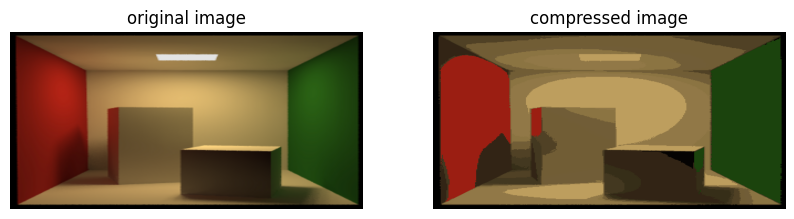

Quality Loss Analysis:
MSE: 186.70855211598746
PSNR: 25.419161497655473


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from minisom import MiniSom

image=Image.open(r"C:\Users\shrey\Downloads\BOX.png").convert('RGB')
image=np.array(image)
pixel=image.reshape(-1,3)/255.0

som=MiniSom(4,4,3,sigma=1,learning_rate=0.5)
som.random_weights_init(pixel)
som.train_random(pixel,100)

new_pixel=[]
for p in pixel:
    x,y=som.winner(p)
    new_pixel.append(som.get_weights()[x,y])

new_pixel=np.array(new_pixel)
compressed=new_pixel.reshape(image.shape)
compressed=(compressed*255).astype(np.uint8)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("original image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(compressed)
plt.title("compressed image")
plt.axis("off")
plt.show()

original=image.astype(float)
compressed=compressed.astype(float)
mse=np.mean((original-compressed)**2)
psnr=10*np.log10((255**2)/mse)
print("Quality Loss Analysis:")
print("MSE:",mse)
print("PSNR:",psnr)